# WP12 — Gerçek S16 kaynak yokluğu kontrolü

Yeni API yoktur; kayıtlı tek yanıt incelenir. Şema ve uygulama kontrolü, ajan okuması ve insan kararı ayrıdır. İki kullanıcı PDF’si korunur; S16 için hiç PDF alıntısı gönderilmemiştir.

Birebir model mesajı:
{"result":{"schema_version":"WP12-local-llm-candidate-v2","language":"tr","status":"refused","refusal_code":"NO_SOURCE","items":[]}}


,model,HTTP,completion,request_ID,saniye,insan
0,gpt-5.4-mini-2026-03-17,200,completed,req_422061244f4b428cac559e597dff0a55,2.047,PENDING


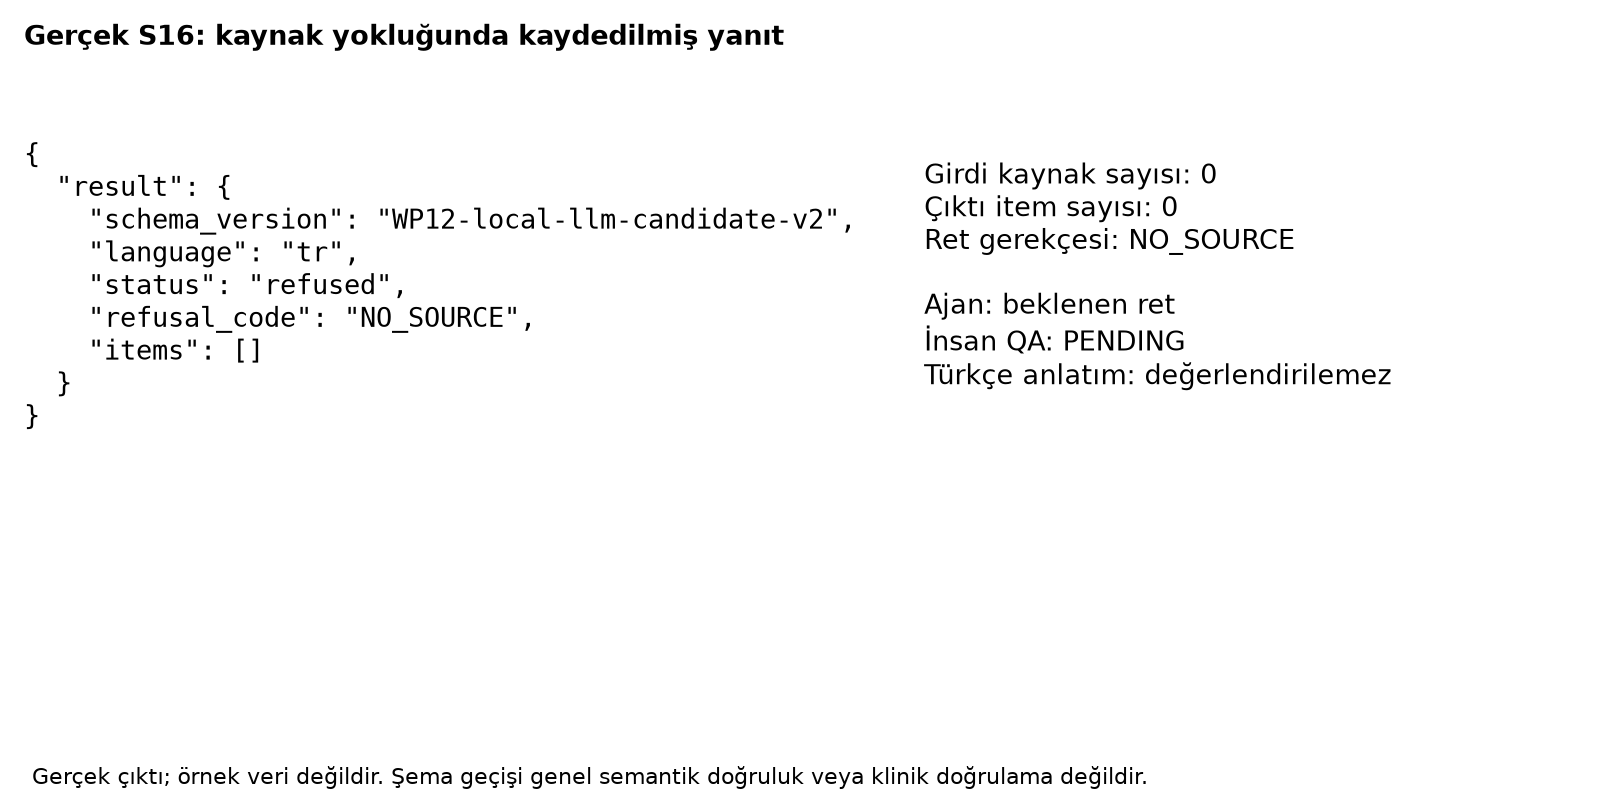

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_S16_actual_review_v1'
F=ROOT/'reports/figures/WP12/openai_S16_actual_review_v1'
r=json.loads((Q/'independent_review.json').read_text(encoding='utf-8'))
print('Birebir model mesajı:\n'+(Q/'exact_model_message.txt').read_text(encoding='utf-8'))
display(pd.DataFrame([{'model':r['model'],'HTTP':r['HTTP_status'],'completion':r['completion_status'],'request_ID':r['API_request_id'],'saniye':r['latency_seconds'],'insan':'PENDING'}]))
from IPython.display import Image
display(Image(filename=str(F/'01_real_no_source_refusal.png')))


**Yorum:** NO_SOURCE ve boş items, frozen boş kaynak koşuluyla uyumludur. Üretilmiş iddia/sayfa/quote yoktur. IMAGE_TEXT_UNAVAILABLE kullanılmamıştır; o S15’in farklı koşuludur. Açıklama cümlesi yokken language=tr alanını Türkçe kalite başarısı saymıyoruz. Sistem ve kabul kriteri bu ret davranışını açıkça istiyor; tek örnek bağımsız halüsinasyon dayanıklılığı testi değildir.

,input,cached,output,reasoning,total,maliyet_USD
0,589,0,50,0,639,0.00066675


,HTTP_reservations_total,inference_reservations_total,reserved_USD,within_limits,unknown_prior_cost_not_refunded,actual_invoice_total
0,15,5,0.115,True,True,UNKNOWN_NOT_QUERIED


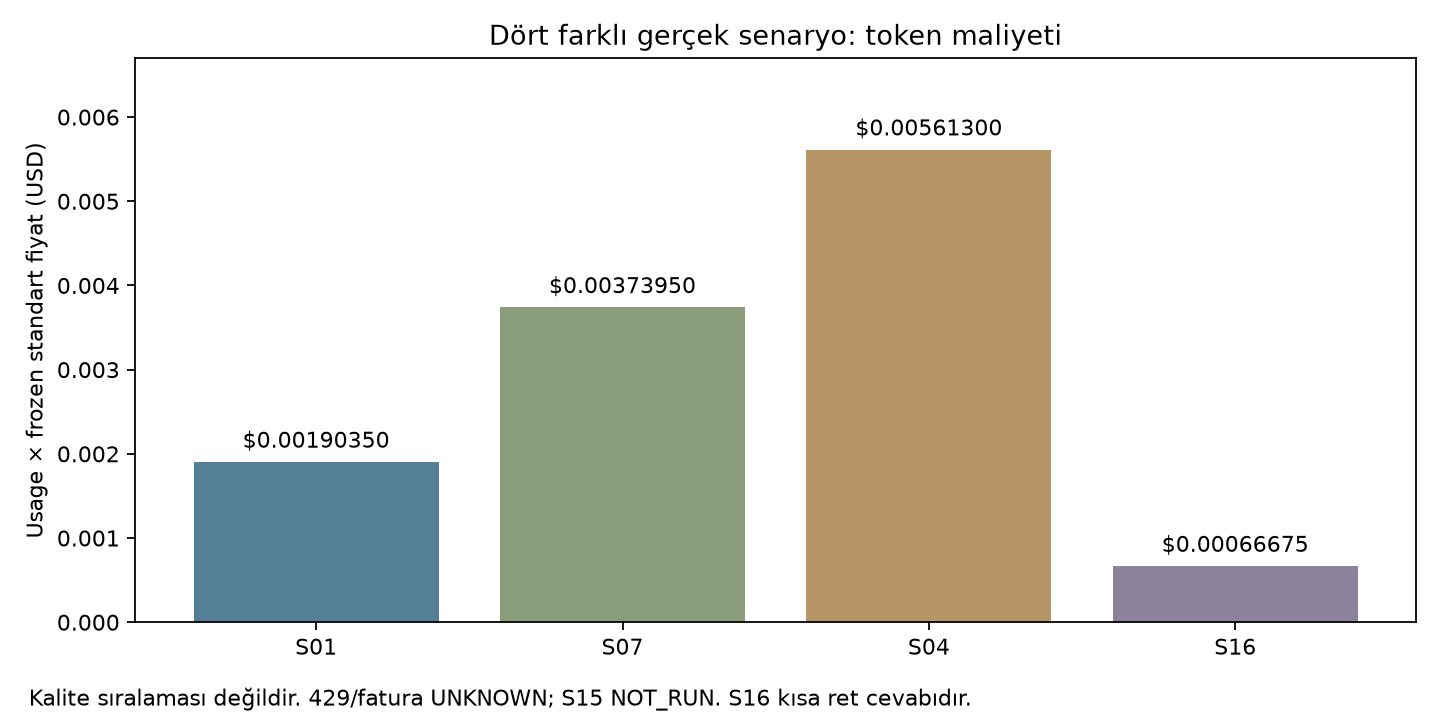

In [2]:

u=r['usage'];display(pd.DataFrame([{'input':u['input_tokens'],'cached':u['input_tokens_details']['cached_tokens'],'output':u['output_tokens'],'reasoning':u['output_tokens_details']['reasoning_tokens'],'total':u['total_tokens'],'maliyet_USD':r['usage_token_cost_USD']}]))
display(pd.DataFrame([r['aggregate_budget']]))
display(Image(filename=str(F/'02_completed_actual_costs.png')))


**Maliyet yorumu:** 589×0.75/1M +50×4.50/1M =0.00066675USD. Dört completed bulut isteğinin bilinen alt toplamı0.01192275USD; kesin fatura değildir. Eski rezervler korunarak15HTTP/5inference/.115USD; tavan30/10/.25USD. Tek kısa ret cevabı maliyet/kalite açısından uzun açıklamalarla eş görevli değildir. RAM/VRAM toplanmadı; kararlılık tek cevaptan ölçülemez.

In [3]:

display(pd.read_csv(Q/'consolidated_review_with_S16.csv'))
display(pd.read_csv(Q/'all_real_runs_comparison.csv').drop(columns=['model_message_exact'],errors='ignore'))
display(pd.DataFrame({'kontrol':list(r['checks']),'sonuç':list(r['checks'].values())}))
display(pd.DataFrame([json.loads((Q/'test_summary.json').read_text(encoding='utf-8'))]))


,scenario,item,physical_page,primary_quote_id,source_quote_exact,model_explanation_exact,agent_source_status,agent_note_tr,Turkish_review,citation_scope,uncertainty_exception,human_decision,automatic_release,prior_table_ref
0,S01,1.0,1.0,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Table...,İlacın adı Erythromycin Tablets BP 250 mg’dir ve etkin madde eritromisindir.,SUPPORTED_PENDING_HUMAN,Tam ürün adı ve etkin madde kaynakta mevcut; macrolide sınıfı aktarılmamış.,Kaynak uyumlu Türkçe; ayrıntı eksikleri,Mevcut birincil kaynak,Uygulanmaz: ürün kimliği,PENDING,False,reports\qa\WP12\openai_S01_success_review_v1\source_claim_comparison.csv
1,S01,2.0,6.0,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red ...,"Erythromycin Tablets kırmızı renkli, yuvarlak, bikonveks ve enterik kaplı tabletlerdir.",SUPPORTED_PENDING_HUMAN,Kırmızı/yuvarlak/bikonveks/enterik kaplı özellikler kaynakta birebir; ambalaj adetleri aktarılma...,Kaynak uyumlu Türkçe; ayrıntı eksikleri,Mevcut birincil kaynak,Uygulanmaz: ürün kimliği,PENDING,False,reports\qa\WP12\openai_S01_success_review_v1\source_claim_comparison.csv
2,S07,1.0,7.0,quote:9882fd3b194817596c0e2b90da5ab49b7b708ce9db09fe072566f2948593d787,Renal Toxicity: Rise in BUN has been reported and is apparently dose related (see WARNINGS). \n,"Bu başlık, tetracyclines sınıfı için renal toksisite bağlamını verir: BUN artışı bildirilmiştir ...",CORE_SUPPORTED_WITH_LANGUAGE_NOTE,tetracyclines sınıf adı İngilizce bırakılmış. BUN bildirimi ve dozla ilişkili olabileceği ifades...,Tam Türkçe başarısı verilmedi; impaired renal function çevrilmemiş,Item2 atıf kapsamı notu; diğer bağlamlar tabloda,İstisnanın iki koşulu korunmuş; dil notu var,PENDING,False,reports\qa\WP12\openai_S07_actual_review_v1\source_claim_comparison.csv
3,S07,2.0,7.0,quote:22b5ff9fea323f22799d18e7da6093aa6c7238b3f20a56f9c5cabade582f5f48,The following adverse reactions have been observed in patients receiving tetracyclines. \n,"Sınıf girişine göre sonraki advers reaksiyonlar tetracyclines alan hastalarda gözlenmiştir; bu, ...",CORE_CLASS_INTRO_SUPPORTED_CITATION_CONTEXT_NOTE,İlk sınıf gözlemi doğrudan alıntıyla destekli. Renal alt başlık/doxycycline yorumu tüm girdi bağ...,Tam Türkçe başarısı verilmedi; impaired renal function çevrilmemiş,Item2 atıf kapsamı notu; diğer bağlamlar tabloda,İstisnanın iki koşulu korunmuş; dil notu var,PENDING,False,reports\qa\WP12\openai_S07_actual_review_v1\source_claim_comparison.csv
4,S07,3.0,4.0,quote:4206e7f12339a5412d16025026794c02964045f0df666b3c4b8ea3f06ca2495b,The antianabolic action of the tetracyclines may cause an increase in BUN. Studies to date indic...,Tetracyclines’in antianabolik etkisi BUN artışına yol açabilir. Mevcut çalışmalara göre bu durum...,CORE_EXCEPTION_SUPPORTED_LANGUAGE_QUALITY_FLAG,May cause → yol açabilir; studies to date indicate → mevcut çalışmalara göre; doxycycline ve ren...,Tam Türkçe başarısı verilmedi; impaired renal function çevrilmemiş,Item2 atıf kapsamı notu; diğer bağlamlar tabloda,İstisnanın iki koşulu korunmuş; dil notu var,PENDING,False,reports\qa\WP12\openai_S07_actual_review_v1\source_claim_comparison.csv
5,S04,1.0,4.0,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,"4. Possible side effects \n \nLike all medicines, this medicine can cause side effects, althoug...","4. bölümde, tüm ilaçlar gibi bu ilacın da yan etki yapabileceği ve herkesin bunu yaşamayabileceğ...",SOURCE_CORE_SUPPORTED_WITH_UNSUPPORTED_TEMPORAL_WORD,"Yan etki olasılığı, herkesin yaşamayabileceği ve acil doktor iletişimi bağlamı korunuyor. Ancak ...","Türkçe açıklama; İngilizce kaynak alıntısı, terim ve dilbilgisi notları",1/2/3 atıf; aynı PDF örtüşen alıntılar,Bilinmeyen sıklık korunmuş; usually aktarımı serbest,PENDING,False,reports\qa\WP12\openai_S0

,model_method,experiment_status,pipeline_terminal_status,independent_content_schema_status,actual_language_agent,source_faithfulness_agent,human_review,actual_server_prompt_tokens,output_tokens,server_total_seconds,raw_response_ref,raw_response_sha256,scenario,formal_human_review,user_positive_statement,preflight_count_only,usage_token_cost_USD,HTTP_latency_seconds,latency_definition,citation_note
0,Gemma V1,FAIL,SCHEMA_OR_SOURCE_VALIDATION_FAILED,PASS,FAIL_ENGLISH,FAIL_CONTRADICTED,PENDING,919.0,188.0,8.708088,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\experim...,8ad96fef1e68c9beb826a3ca343d44104bd4069d4002768122f04f127449e3b2,S01,PENDING,NaN,NaN,NaN,NaN,NaN,NaN
1,Gemma V2,FAIL,TOKEN_COUNT_ALIGNMENT_FAILED,PASS,FAIL_ENGLISH,CORE_SUPPORTED_OMISSIONS,PENDING,729.0,312.0,8.157021,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\gemma_v...,5921534f455a1e5fcc9f3a105a5de4cd15575fce8bb671f9a60a6842c0523638,S01,PENDING,NaN,NaN,NaN,NaN,NaN,NaN
2,Qwen3 4B,NOT_RUN,BLOCKED_HOST_RAM_AND_TOKEN_API_PREREQUISITES,NOT_RUN,NOT_RUN,NOT_RUN,PENDING,NaN,NaN,NaN,NaN,NaN,S01,PENDING,NaN,NaN,NaN,NaN,NaN,NaN
3,OpenAI / first account,API_BILLING_BLOCKED_NO_MODEL_OUTPUT,HTTP429 credit_balance_exhausted,NOT_EVALUABLE,NOT_EVALUABLE,NOT_EVALUABLE,PENDING_NO_OUTPUT,NaN,NaN,NaN,NaN,NaN,S01,PENDING,NaN,1236.0,NaN,NaN,NaN,NaN
4,gpt-5.4-mini-2026-03-17 / corrected account,COMPLETED_PENDING_HUMAN,HTTP200 completed,PASS,TURKISH_SUPPORTED_SOURCE_PROPER_NAMES_RETAINED,SUPPORTED_FOR_TWO_RETURNED_ITEMS,PENDING,1236.0,217.0,NaN,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\openai_...,57915e6d706b4ba88afcada79518454a30b6ccd215912b14e2d95e9e24c6a16d,S01,PENDING,SEPARATE_RECEIPT_FOR_TWO_ITEMS,NaN,0.001904,3.953,HTTP client wall duration; local Gemma server-duration is a different measure,NaN
5,gpt-5.4-mini-2026-03-17,COMPLETED_WITH_AGENT_QUALITY_FLAGS,HTTP200 completed / technical PASS,NaN,NOT_FULL_PASS_UNTRANSLATED_CRITICAL_CONDITION,CLASS_SCOPE_AND_BOTH_EXCEPTION_CLAUSES_RETAINED_WITH_NOTES,PENDING,1962.0,504.0,NaN,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\openai_...,6586f01ecf0160bbf0a30638897d2c9b81af7cf2bf307f5c38a82137b07ac904,S07,PENDING,NaN,NaN,0.003740,4.813,NaN,ITEM2_CONTEXT_REFERENCE_REVIEW_NOTE_NOT_SCHEMA_FAILURE
6,gpt-5.4-mini-2026-03-17,COMPLETED_WITH_AGENT_REVIEW_NOTES,HTTP200 completed / technical PASS,NaN,TURKISH_EXPLANATION_WITH_QUOTED_ENGLISH_MEDICAL_TERMS_AND_STYLE_NOTES,UNKNOWN_FREQUENCY_AND_PAGE4_CONTEXT_RETAINED_WITH_QUALIFIER_NOTES,PENDING,2828.0,776.0,NaN,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\openai_...,acbafb53ffb8c937d5d1589a979d165b35ae654f94263b424653443b9edc6138,S04,PENDING,NaN,NaN,0.005613,5.203,NaN,NaN
7,gpt-5.4-mini-2026-03-17,COMPLETED_EXPECTED_REFUSAL_AGENT_PENDING_HUMAN,HTTP200 completed / schema and application PASS,NaN,NOT_EVALUABLE_NO_EXPLANATION_TEXT,EXPECTED_NO_SOURCE_REFUSAL_NO_GENERATED_CLAIMS_IN_THIS_RESPONSE,NaN,589.0,50.0,NaN,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\openai_...,776cebb1d7f73e54e07d7127876b7b11191405ce1abf94ff3e8b599323f8f15b,S16,PENDING,NaN,NaN,0.000667,2.047,NaN,NaN
8,gpt-5.4-mini planned,NOT_RUN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,S15,PENDING,NaN,NaN,NaN,NaN,NaN,NaN


,kontrol,sonuç
0,raw_manifest_and_inventory,True
1,raw_response_hash,True
2,frozen_request_and_no_source_payload,True
3,prompt_and_execution_hash,True
4,raw_JSON_and_recomputed_assessment,True
5,schema_and_application,True
6,expected_refusal_no_claims,True
7,completed_model_and_IDs,True
8,single_inference_three_HTTP200,True
9,exact_token_count_and_limits,True


,tests,returncode,API_requests
0,10,0,0


**Sınırlar ve durma:** 10 ağsız teknik test PASS; yanlış ret gerekçesi schema geçse de uygulama kontrolünden geçmez. Bu genel semantik classifier değildir. İnsan kararı PENDING; S01/S07/S04 kalite notları, GemmaV1/V2 FAIL, QwenNOT_RUN ve ilk429 değişmez. S15 NOT_RUN; yeni senaryo, otomatik tekrar/yayın,19×3,eğitim veya WP13 uygulaması yoktur.